In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon
import os
import sys

sys.path.append("..")
from src.py.proj_conf import *

## Read in Basinmaker Routing Product and WSC Outlet Point

In [12]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file(DATA_RAW + "Basinmaker_RoutingProduct/drainage_region_0004_00015_v2-1/finalcat_info_v2-1.shp")

# Read WSC outlet point metadata
wsc_dp = pd.read_csv(DATA_RAW + "WSC_data/station_metadata_historical.csv")


## Select Manning Cannal Subbasins

In [13]:
# Convert csv to geodataframe
wsc_dp_gdf = gpd.GeoDataFrame(
    wsc_dp,
    geometry = gpd.points_from_xy(
        x = wsc_dp.Longitude,
        y = wsc_dp.Latitude,
        crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    )
)

In [31]:
# Identify initial subbasin containing WSC outlet point
point = wsc_dp_gdf.geometry
basins_gdf['contains_point'] = gdf.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
dp = wsc_basins['SubId'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

ValueError: 'right_df' should be GeoDataFrame, got <class 'geopandas.geoseries.GeoSeries'>

In [7]:


# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in gdf.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in gdf.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

# Create geodataframe containing Manning Canal subbasins
mc_gdf = gdf[gdf['SubId'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

C:\Users\tsaleh\AppData\Local\Temp\ipykernel_17520\3478328845.py:13: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  gdf['contains_point'] = gdf.geometry.contains(point)


NameError: name 'dp' is not defined

## Delineate Upper Manning with Whitebox

In [212]:
import sys
!{sys.executable} -m pip install whitebox
import whitebox
wbt = whitebox.WhiteboxTools()

import math
import rasterio
import rasterio.plot

.\whitebox_tools.exe --run="FillDepressions" --wd="\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_filldep.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 12%
Finding pit cells: 25%
Finding pit cells: 37%
Finding pit cells: 50%
Finding pit cells: 62%
Finding pit cells: 75%
Finding pit cells: 87%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%

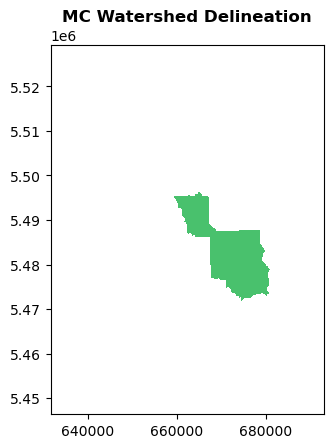

<Axes: title={'center': 'MC Watershed Delineation'}>

In [274]:
# Set working directory
wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

# Fill depressions in DEM
wbt.fill_depressions(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_filldep.tif",
    fix_flats=True,
    flat_increment=None,
    max_depth=None
)

# Create flow accumulation raster
wbt.d8_flow_accumulation(
    i = "mc_filldep.tif", 
    output = "mc_flowaccgrid.tif", 
    out_type="cells", 
    log=False, 
    clip=False, 
    pntr=False, 
    esri_pntr=False
)

# Extract streams from flow accumulation raster
wbt.extract_streams(
    flow_accum='mc_flowaccgrid.tif', 
    output='mc_streams_100000.tif', 
    threshold=100000.000000, 
    zero_background=True, 
)

# Create flow pointer (flow direction) raster
wbt.d8_pointer(
    dem = "mc_filldep.tif",
    output = "mc_flowpointergrid.tif",
    esri_pntr=False
)

# Snap pour points to stream network
wbt.jenson_snap_pour_points(
    pour_pts = "mc_pp_extract.shp", 
    streams = "mc_flowaccgrid.tif", 
    output = "mc_pp_snap_500m.shp", 
    snap_dist = 500.0
)

# Derive watershed areas
wbt.watershed(
    d8_pntr = 'mc_flowpointergrid.tif', 
    pour_pts = 'mc_pp_snap_500m.shp', 
    output = 'mc_watershed.tif', 
    esri_pntr=False
)

# Visualize Manning Canal watershed raster
data_name = "/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/mc_watershed.tif"
tiff = rasterio.open(data_name)
rasterio.plot.show(tiff, title = "MC Watershed Delineation")